In [1]:

import pandas as pd

df = pd.read_csv("advertising.csv")

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

print(df.head())


      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [2]:

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())


Missing Values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
Duplicate Rows: 0


In [3]:

print(df.dtypes)


TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [4]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 160
Testing rows: 40


In [5]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])


Scaled Training Data:
[[-0.40424839 -1.02823707 -0.33767538]
 [ 0.32060772 -0.91982774 -1.16143931]
 [-1.27051084  0.2591237   0.25425079]
 [-1.04235941 -0.6962335  -0.57444585]
 [ 0.8791034  -1.38734296 -0.70762924]]


In [6]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

y_pred_linear = linear_model.predict(X_test_scaled)

print("Linear Regression")
print("R2 Score:", r2_score(y_test, y_pred_linear))
print("MSE:", mean_squared_error(y_test, y_pred_linear))


Linear Regression
R2 Score: 0.9059011844150826
MSE: 2.9077569102710923


In [7]:

from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

y_pred_poly = poly_model.predict(X_test_poly)

print("Polynomial Regression")
print("R2 Score:", r2_score(y_test, y_pred_poly))
print("MSE:", mean_squared_error(y_test, y_pred_poly))


Polynomial Regression
R2 Score: 0.9533174341074797
MSE: 1.4425426369013599


In [8]:

from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_scaled, y_train)

y_pred_lasso = lasso_model.predict(X_test_scaled)

print("Lasso Regression")
print("R2 Score:", r2_score(y_test, y_pred_lasso))
print("MSE:", mean_squared_error(y_test, y_pred_lasso))


Lasso Regression
R2 Score: 0.905176577782095
MSE: 2.930148052297701


In [9]:

from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)

y_pred_ridge = ridge_model.predict(X_test_scaled)

print("Ridge Regression")
print("R2 Score:", r2_score(y_test, y_pred_ridge))
print("MSE:", mean_squared_error(y_test, y_pred_ridge))


Ridge Regression
R2 Score: 0.9056564972278859
MSE: 2.9153180135113756


In [10]:

from sklearn.linear_model import ElasticNet

elastic_model = ElasticNet(alpha=0.1, l1_ratio=0.5)
elastic_model.fit(X_train_scaled, y_train)

y_pred_elastic = elastic_model.predict(X_test_scaled)

print("Elastic Net Regression")
print("R2 Score:", r2_score(y_test, y_pred_elastic))
print("MSE:", mean_squared_error(y_test, y_pred_elastic))


Elastic Net Regression
R2 Score: 0.9013373177887236
MSE: 3.0487854092788718


In [11]:

results = pd.DataFrame({
    "Model": ["Linear", "Polynomial", "Lasso", "Ridge", "Elastic Net"],
    "R2": [
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_poly),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_elastic)
    ],
    "MSE": [
        mean_squared_error(y_test, y_pred_linear),
        mean_squared_error(y_test, y_pred_poly),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_elastic)
    ]
})

results.sort_values("R2", ascending=False)


,Model,R2,MSE
1,Polynomial,0.953317,1.442543
0,Linear,0.905901,2.907757
3,Ridge,0.905656,2.915318
2,Lasso,0.905177,2.930148
4,Elastic Net,0.901337,3.048785


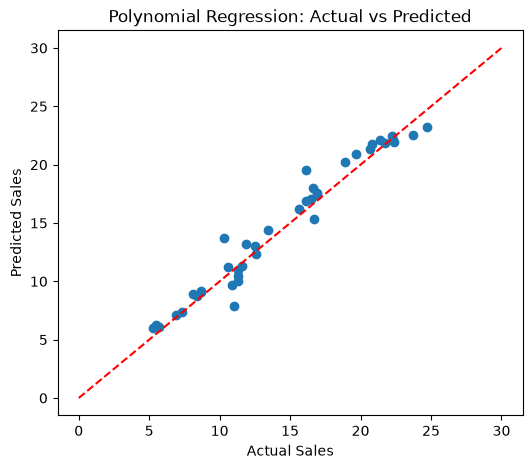

In [12]:

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.scatter(y_test, y_pred_poly)

plt.plot([0, 30], [0, 30], "r--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Polynomial Regression: Actual vs Predicted")

plt.show()


In [13]:

print("Best Model: Polynomial Regression")

print("Intercept:", poly_model.intercept_)

print("\nCoefficients:")
for name, coef in zip(
    poly.get_feature_names_out(X.columns),
    poly_model.coef_
):
    print(name, "=", round(coef, 4))


Best Model: Polynomial Regression
Intercept: 15.683162223214335

Coefficients:
TV = 4.4837
Radio = 1.5053
Newspaper = 0.0633
TV^2 = -0.7493
TV Radio = 0.5198
TV Newspaper = -0.0436
Radio^2 = 0.3155
Radio Newspaper = 0.0493
Newspaper^2 = 0.035


In [14]:

selected = X_test.sample(n=5, random_state=42)

scaled_five = scaler.transform(selected)
poly_five = poly.transform(scaled_five)
predicted_five = poly_model.predict(poly_five)

comparison = selected.copy()
comparison["Actual Sales"] = y.loc[selected.index]
comparison["Predicted Sales"] = predicted_five

print(comparison.round(3))


        TV  Radio  Newspaper  Actual Sales  Predicted Sales
68   237.4   27.5       11.0          18.9           20.202
56     7.3   28.1       41.4           5.5            6.283
177  170.2    7.8       35.2          16.7           15.382
84   213.5   43.0       33.8          21.7           21.833
128  220.3   49.0        3.2          24.7           23.237


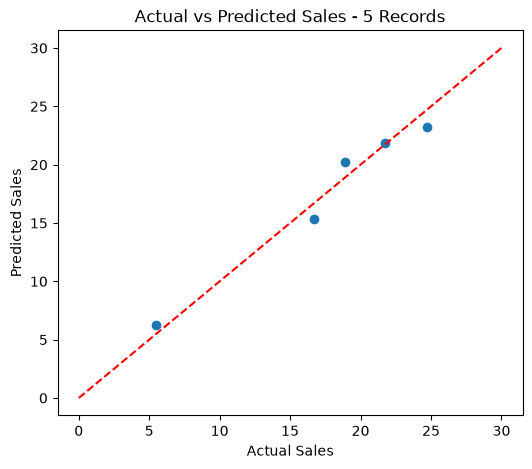

In [15]:

plt.figure(figsize=(6, 5))

plt.scatter(
    comparison["Actual Sales"],
    comparison["Predicted Sales"]
)

plt.plot([0, 30], [0, 30], "r--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - 5 Records")

plt.show()


In [16]:

scaled_table = pd.DataFrame(
    scaled_five,
    columns=["zTV", "zRadio", "zNewspaper"],
    index=selected.index
)

print(scaled_table.round(4))


        zTV  zRadio  zNewspaper
68   1.0383  0.3133     -0.9345
56  -1.6959  0.3540      0.5650
177  0.2398 -1.0215      0.2592
84   0.7543  1.3635      0.1901
128  0.8351  1.7701     -1.3193


In [17]:

df["Sales_Category"] = (df["Sales"] >= 16).astype(int)

print(df[["Sales", "Sales_Category"]].head())

print("Category Counts:")
print(df["Sales_Category"].value_counts())


   Sales  Sales_Category
0   22.1               1
1   10.4               0
2   12.0               0
3   16.5               1
4   17.9               1
Category Counts:
Sales_Category
1    101
0     99
Name: count, dtype: int64


In [18]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_class = df[["TV", "Radio", "Newspaper"]]
y_class = df["Sales_Category"]

X_train_cl, X_test_cl, y_train_cl, y_test_cl = train_test_split(
    X_class, y_class, test_size=0.2,
    random_state=42, stratify=y_class
)

class_scaler = StandardScaler()
X_train_cl = class_scaler.fit_transform(X_train_cl)
X_test_cl = class_scaler.transform(X_test_cl)

print("Training:", len(X_train_cl))
print("Testing:", len(X_test_cl))


Training: 160
Testing: 40


In [19]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_cl, y_train_cl)

y_pred_log = log_model.predict(X_test_cl)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test_cl, y_pred_log))
print("Precision:", precision_score(y_test_cl, y_pred_log))
print("Recall:", recall_score(y_test_cl, y_pred_log))
print("F1 Score:", f1_score(y_test_cl, y_pred_log))
print("Confusion Matrix:")
print(confusion_matrix(y_test_cl, y_pred_log))


Logistic Regression
Accuracy: 0.95
Precision: 1.0
Recall: 0.9
F1 Score: 0.9473684210526315
Confusion Matrix:
[[20  0]
 [ 2 18]]


In [20]:

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_cl, y_train_cl)

y_pred_knn = knn_model.predict(X_test_cl)

print("KNN Classification")
print("Accuracy:", accuracy_score(y_test_cl, y_pred_knn))
print("Precision:", precision_score(y_test_cl, y_pred_knn))
print("Recall:", recall_score(y_test_cl, y_pred_knn))
print("F1 Score:", f1_score(y_test_cl, y_pred_knn))
print("Confusion Matrix:")
print(confusion_matrix(y_test_cl, y_pred_knn))


KNN Classification
Accuracy: 0.95
Precision: 1.0
Recall: 0.9
F1 Score: 0.9473684210526315
Confusion Matrix:
[[20  0]
 [ 2 18]]


In [21]:

from sklearn.svm import SVC

svm_model = SVC(kernel="rbf")
svm_model.fit(X_train_cl, y_train_cl)

y_pred_svm = svm_model.predict(X_test_cl)

print("SVM Classification")
print("Accuracy:", accuracy_score(y_test_cl, y_pred_svm))
print("Precision:", precision_score(y_test_cl, y_pred_svm))
print("Recall:", recall_score(y_test_cl, y_pred_svm))
print("F1 Score:", f1_score(y_test_cl, y_pred_svm))
print("Confusion Matrix:")
print(confusion_matrix(y_test_cl, y_pred_svm))


SVM Classification
Accuracy: 0.95
Precision: 1.0
Recall: 0.9
F1 Score: 0.9473684210526315
Confusion Matrix:
[[20  0]
 [ 2 18]]


In [22]:

from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_cl, y_train_cl)

y_pred_tree = tree_model.predict(X_test_cl)

print("Decision Tree Classification")
print("Accuracy:", accuracy_score(y_test_cl, y_pred_tree))
print("Precision:", precision_score(y_test_cl, y_pred_tree))
print("Recall:", recall_score(y_test_cl, y_pred_tree))
print("F1 Score:", f1_score(y_test_cl, y_pred_tree))
print("Confusion Matrix:")
print(confusion_matrix(y_test_cl, y_pred_tree))


Decision Tree Classification
Accuracy: 0.9
Precision: 1.0
Recall: 0.8
F1 Score: 0.8888888888888888
Confusion Matrix:
[[20  0]
 [ 4 16]]


In [23]:

from sklearn.ensemble import RandomForestClassifier

forest_model = RandomForestClassifier(
    n_estimators=100, random_state=42
)
forest_model.fit(X_train_cl, y_train_cl)

y_pred_forest = forest_model.predict(X_test_cl)

print("Random Forest Classification")
print("Accuracy:", accuracy_score(y_test_cl, y_pred_forest))
print("Precision:", precision_score(y_test_cl, y_pred_forest))
print("Recall:", recall_score(y_test_cl, y_pred_forest))
print("F1 Score:", f1_score(y_test_cl, y_pred_forest))
print("Confusion Matrix:")
print(confusion_matrix(y_test_cl, y_pred_forest))


Random Forest Classification
Accuracy: 0.925
Precision: 1.0
Recall: 0.85
F1 Score: 0.918918918918919
Confusion Matrix:
[[20  0]
 [ 3 17]]


In [24]:

models = {
    "Logistic Regression": y_pred_log,
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_forest
}

class_results = []

for name, pred in models.items():
    class_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_cl, pred),
        "Precision": precision_score(y_test_cl, pred),
        "Recall": recall_score(y_test_cl, pred),
        "F1 Score": f1_score(y_test_cl, pred)
    })

class_results = pd.DataFrame(class_results)

print(class_results.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.950        1.0    0.90    0.9474
                KNN     0.950        1.0    0.90    0.9474
                SVM     0.950        1.0    0.90    0.9474
      Decision Tree     0.900        1.0    0.80    0.8889
      Random Forest     0.925        1.0    0.85    0.9189


In [25]:

for name, pred in models.items():
    cm = confusion_matrix(y_test_cl, pred)
    errors = cm[0, 1] + cm[1, 0]

    print(name)
    print("Confusion Matrix:")
    print(cm)
    print("Total Errors:", errors)
    print("--------------------")


Logistic Regression
Confusion Matrix:
[[20  0]
 [ 2 18]]
Total Errors: 2
--------------------
KNN
Confusion Matrix:
[[20  0]
 [ 2 18]]
Total Errors: 2
--------------------
SVM
Confusion Matrix:
[[20  0]
 [ 2 18]]
Total Errors: 2
--------------------
Decision Tree
Confusion Matrix:
[[20  0]
 [ 4 16]]
Total Errors: 4
--------------------
Random Forest
Confusion Matrix:
[[20  0]
 [ 3 17]]
Total Errors: 3
--------------------


In [26]:

predicted_counts = pd.Series(y_pred_log).value_counts()

print("Low Sales (0):", predicted_counts.get(0, 0))
print("High Sales (1):", predicted_counts.get(1, 0))


Low Sales (0): 22
High Sales (1): 18


In [27]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

cluster_data = df[["TV", "Radio", "Newspaper"]]

cluster_scaler = StandardScaler()
cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Dataset Shape:", cluster_scaled.shape)
print("Clustering Data Ready")


Dataset Shape: (200, 3)
Clustering Data Ready


In [28]:

from sklearn.metrics import silhouette_score

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(cluster_scaled)

    score = silhouette_score(cluster_scaled, labels)

    print("Clusters:", k, "Silhouette Score:", round(score, 4))


C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Clusters: 2 Silhouette Score: 0.3298
Clusters: 3 Silhouette Score: 0.3051
Clusters: 4 Silhouette Score: 0.299
Clusters: 5 Silhouette Score: 0.3191


C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Clusters: 6 Silhouette Score: 0.3016
Clusters: 7 Silhouette Score: 0.2937
Clusters: 8 Silhouette Score: 0.278


C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [29]:

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(cluster_scaled)

print("Cluster Counts:")
print(df["Cluster"].value_counts())


Cluster Counts:
Cluster
1    135
0     65
Name: count, dtype: int64


C:\Users\Huawei\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


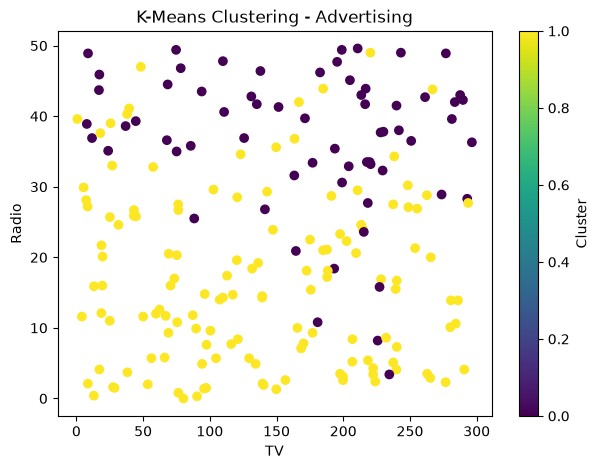

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(
    df["TV"],
    df["Radio"],
    c=df["Cluster"],
    cmap="viridis"
)

plt.xlabel("TV")
plt.ylabel("Radio")
plt.title("K-Means Clustering - Advertising")
plt.colorbar(label="Cluster")
plt.show()


In [31]:

cluster_summary = df.groupby("Cluster")[
    ["TV", "Radio", "Newspaper", "Sales"]
].mean()

print("Cluster Analysis:")
print(cluster_summary.round(2))


Cluster Analysis:
             TV  Radio  Newspaper  Sales
Cluster                                 
0        171.00  36.81      53.97   18.1
1        135.51  16.74      19.28   13.7


In [32]:

import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="KMeans is known to have a memory leak on Windows"
    )

    for k in range(2, 9):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(cluster_scaled)
        score = silhouette_score(cluster_scaled, labels)
        print("Clusters:", k, "Score:", round(score, 4))


Clusters: 2 Score: 0.3298
Clusters: 3 Score: 0.3051
Clusters: 4 Score: 0.299
Clusters: 5 Score: 0.3191
Clusters: 6 Score: 0.3016
Clusters: 7 Score: 0.2937
Clusters: 8 Score: 0.278
